<a href="https://colab.research.google.com/github/Kjotas/PID-ControlesII-Project/blob/main/graficos/PID_Graf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Caso                         Sobressinal   Acomodação (±2%)
Malha aberta                        0,0%             20,8 s
Ziegler–Nichols                    54,1%              7,2 s
Ajuste final                        0,9%              4,3 s


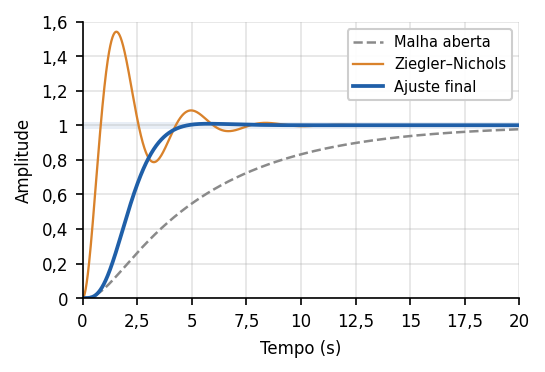

Caso                         Sobressinal   Acomodação (±2%)
Arduino, degrau de 0 a 1 V          1,3%              4,5 s
Arduino, degrau de 1 a 3 V          0,7%              5,6 s


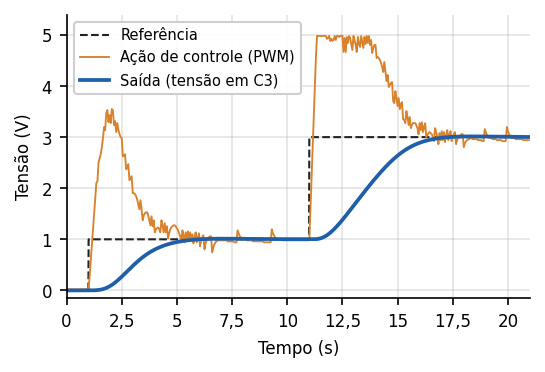

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
"""
Graficos do relatorio: controle PID de tensao em uma planta RC de 3a ordem
Pronto para o Google Colab: cole todo o conteudo numa celula e execute.
Gera fig_degrau.png e fig_curva_arduino.png em /content, mostra os graficos,
imprime a tabela de desempenho e baixa as figuras.
"""
# Bibliotecas (numpy, scipy e matplotlib ja vem instaladas no Colab)
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import signal
from scipy.linalg import expm

# Planta: G(s) = 1 / (s^3 + 5 s^2 + 6 s + 1), com R = 10 kOhm e C = 100 uF (RC = 1 s)
DEN_G = np.array([1.0, 5.0, 6.0, 1.0])
A = np.array([[-2, 1, 0], [1, -2, 1], [0, 1, -1]], float)   # estados: v1, v2, v3
B = np.array([1, 0, 0], float)

# Ziegler-Nichols (Kcr e Pcr por Routh-Hurwitz) e ajuste final
KCR, PCR = 29.0, 2 * np.pi / np.sqrt(6)
ZN = (0.6 * KCR, 0.5 * PCR, 0.125 * PCR)
KP, TI, TD = 12.0, 2.0, 0.5
N_FILTRO = 5.0
TS = 0.01                                   # periodo de amostragem do Arduino [s]

PASTA = Path.cwd()                          # no Colab: /content
VIRGULA = mticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
plt.rcParams.update({"font.size": 8, "axes.labelsize": 8, "legend.fontsize": 7, "axes.grid": True,
                     "grid.alpha": 0.35, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 150})


def br(valor, casas=1):
    return f"{valor:.{casas}f}".replace(".", ",")


def malha_fechada(kp, ti, td, b, c):
    """Y/R do PID com pesos b e c na referencia (b = c = 1: classico; b = c = 0: I-PD)."""
    den = np.polyadd(np.polymul([ti, 0.0], DEN_G), kp * np.array([ti * td, ti, 1.0]))
    num = np.trim_zeros(kp * np.array([c * ti * td, b * ti, 1.0]), "f")
    return num, den


def metricas(t, y, t0=0.0, y0=0.0, yf=1.0):
    """Sobressinal (%) e tempo de acomodacao na faixa de +-2% (s) de um degrau em t0."""
    m = t >= t0
    tt, yn = t[m] - t0, (y[m] - y0) / (yf - y0)
    mp = max(0.0, (yn.max() - 1) * 100)
    fora = np.where(np.abs(yn - 1) > 0.02)[0]
    ts = tt[fora[-1] + 1] if len(fora) else 0.0
    return mp, ts


def simula_arduino(perfil, tfim, sub=10):
    """Repete o laco do sketch: ADC de 10 bits, PID na forma I-PD com derivada filtrada,
    anti-windup por integracao condicional, saturacao em 0-5 V e PWM de 8 bits limitado
    a 1-254. O PWM entra pelo valor medio, e a planta e integrada de forma exata
    (segurador de ordem zero) com passo TS/sub."""
    h = TS / sub
    ad_m = expm(A * h)
    bd_m = np.linalg.solve(A, (ad_m - np.eye(3)) @ B)
    tf = TD / N_FILTRO
    a_d, b_d = tf / (tf + TS), KP * TD / (tf + TS)
    x = np.zeros(3)
    integral = deriv = 0.0
    y_ant = None
    n = int(round(tfim / TS))
    t_amostra, sp_v, u_v = np.zeros(n), np.zeros(n), np.zeros(n)
    t_fino, y_fino = np.zeros(n * sub), np.zeros(n * sub)
    for k in range(n):
        t = k * TS
        y = min(max(np.floor(x[2] * 1024 / 5), 0), 1023) * 5 / 1023   # leitura em A0
        sp = perfil(t)
        e = sp - y
        if y_ant is None:
            y_ant = y
        p = -KP * y                                  # I-PD: P e D sobre a saida
        deriv = a_d * deriv - b_d * (y - y_ant)
        y_ant = y
        u_pid = p + integral + deriv
        u = min(max(u_pid, 0.0), 5.0)
        if (u_pid < 5.0 or e < 0) and (u_pid > 0.0 or e > 0):
            integral += KP * TS / TI * e
        duty = min(max(int(u * 255 / 5 + 0.5), 1), 254)
        u_pwm = duty * 5 / 255
        t_amostra[k], sp_v[k], u_v[k] = t, sp, u_pwm
        for j in range(sub):
            t_fino[k * sub + j], y_fino[k * sub + j] = t + j * h, x[2]
            x = ad_m @ x + bd_m * u_pwm
    return t_amostra, sp_v, u_v, t_fino, y_fino


t = np.linspace(0, 40, 8001)
curvas = [("Malha aberta", (np.array([1.0]), DEN_G), "#8a8a8a", "--", 1.2),
          ("Ziegler–Nichols", malha_fechada(*ZN, 1, 1), "#d9822b", "-", 1.1),
          ("Ajuste final", malha_fechada(KP, TI, TD, 0, 0), "#1f5fa8", "-", 1.8)]

print(f"{'Caso':<28}{'Sobressinal':>12}{'Acomodação (±2%)':>19}")
fig1, ax = plt.subplots(figsize=(3.5, 2.35))
ax.axhspan(0.98, 1.02, color="#1f5fa8", alpha=0.10, lw=0)
for nome, (num, den), cor, estilo, lw in curvas:
    y = signal.step((num, den), T=t)[1]
    mp, ts = metricas(t, y)
    print(f"{nome:<28}{br(mp) + '%':>12}{br(ts) + ' s':>19}")
    ax.plot(t, y, color=cor, ls=estilo, lw=lw, label=nome)
ax.set(xlim=(0, 20), ylim=(0, 1.6), xlabel="Tempo (s)", ylabel="Amplitude")
ax.legend(loc="upper right", framealpha=0.95)
ax.xaxis.set_major_formatter(VIRGULA)
ax.yaxis.set_major_formatter(VIRGULA)
fig1.tight_layout(pad=0.3)
fig1.savefig(PASTA / "fig_degrau.png", dpi=300)
plt.show()


def perfil(tt):
    return 0.0 if tt < 1.0 else (1.0 if tt < 11.0 else 3.0)   # degraus de 0 a 1 V e de 1 a 3 V


ta, sp, u, tf, yf = simula_arduino(perfil, 21.0)

print(f"{'Caso':<28}{'Sobressinal':>12}{'Acomodação (±2%)':>19}")
for nome, t0, y0, yfim, tmax in (("Arduino, degrau de 0 a 1 V", 1.0, 0.0, 1.0, 11.0),
                                 ("Arduino, degrau de 1 a 3 V", 11.0, 1.0, 3.0, 21.0)):
    sel = tf < tmax
    mp, ts = metricas(tf[sel], yf[sel], t0, y0, yfim)
    print(f"{nome:<28}{br(mp) + '%':>12}{br(ts) + ' s':>19}")

fig2, ax = plt.subplots(figsize=(3.5, 2.35))
ax.plot(ta, sp, color="#222", ls="--", lw=1.0, label="Referência")
ax.plot(ta[::5], u[::5], color="#d9822b", lw=0.9, label="Ação de controle (PWM)")
ax.plot(tf, yf, color="#1f5fa8", lw=1.8, label="Saída (tensão em C3)")
ax.set(xlim=(0, 21), ylim=(-0.15, 5.4), xlabel="Tempo (s)", ylabel="Tensão (V)")
ax.legend(loc="upper left", framealpha=0.95)
ax.xaxis.set_major_formatter(VIRGULA)
ax.yaxis.set_major_formatter(VIRGULA)
fig2.tight_layout(pad=0.3)
fig2.savefig(PASTA / "fig_curva_arduino.png", dpi=300)
plt.show()


# Baixa as figuras quando executado no Google Colab
try:
    from google.colab import files
    files.download(str(PASTA / "fig_degrau.png"))
    files.download(str(PASTA / "fig_curva_arduino.png"))
except ImportError:
    print(f"Figuras salvas em: {PASTA}")